# Activité Pratique N°5 — Agentic AI et MCP
## Partie D : Travail de synthèse — Service après-vente multi-agents

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

**Cas :** le SAV d'un distributeur d'appareils électroniques automatise deux types de demandes :
- **documentation** : dépannage à partir d'une question et, éventuellement, d'une **photo** de l'écran de l'appareil ;
- **garantie** : vérification à partir d'un **numéro de série**.

```
                               ┌──────────────────────────────┐
  demande (+ image_ref) ──────►│  ORCHESTRATEUR (LangGraph)    │──── réponse finale ──► END
                               │  classe la demande, une seule │
                               │  catégorie, choisit l'agent   │
                               └───────┬──────────────▲───────┘
                     documentation     │              │ rend la main
                 ┌─────────────────────┴──┐   ┌───────┴───────────────┐
                 │ agent_documentaire      │   │ agent_garantie         │
                 │ client MCP              │   │ tool LOCAL             │
                 │  └─ tool DISTANT        │   │  consulter_garantie    │
                 │     rag_multimodal      │   │  (registre en lecture  │
                 └──────────┬──────────────┘   │   seule)               │
                            │ streamable-http  └────────────────────────┘
                 ┌──────────▼──────────────────────────────┐
                 │ Serveur MCP (sav/serveur_mcp_rag.py)     │
                 │  agent RAG multimodal : passages + figures│
                 │  des manuels, photo client → réponse      │
                 │  sourcée                                  │
                 └──────────────────────────────────────────┘
```

| Fichier | Rôle |
|---|---|
| `sav/donnees/manuels/*.md` | Manuels de l'imprimante PX-200 et du scanner SC-10 |
| `sav/donnees/figures/` | Figures des manuels + `figures.json` (identifiant, légende, section) |
| `sav/donnees/images_clients/img_px200_01.png` | Photo de l'écran envoyée par le client (exemple 1) |
| `sav/donnees/registre_garanties.json` | Registre des garanties (consulté en lecture seule) |
| `sav/generer_donnees.py` | Génère les figures et la photo (Pillow) |
| `sav/rag_multimodal.py` | Agent RAG multimodal (index texte + figures, LLM vision) |
| `sav/serveur_mcp_rag.py` | Serveur MCP qui publie le tool `rag_multimodal` |

In [1]:
import json
import operator
import os
import socket
import subprocess
import sys
import time
from datetime import date
from pathlib import Path
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, Markdown, display

load_dotenv(override=True)
DONNEES = Path("sav/donnees")

## 1. Les données

**Photo envoyée par le client** (référence `img_px200_01`) et figure correspondante du manuel :

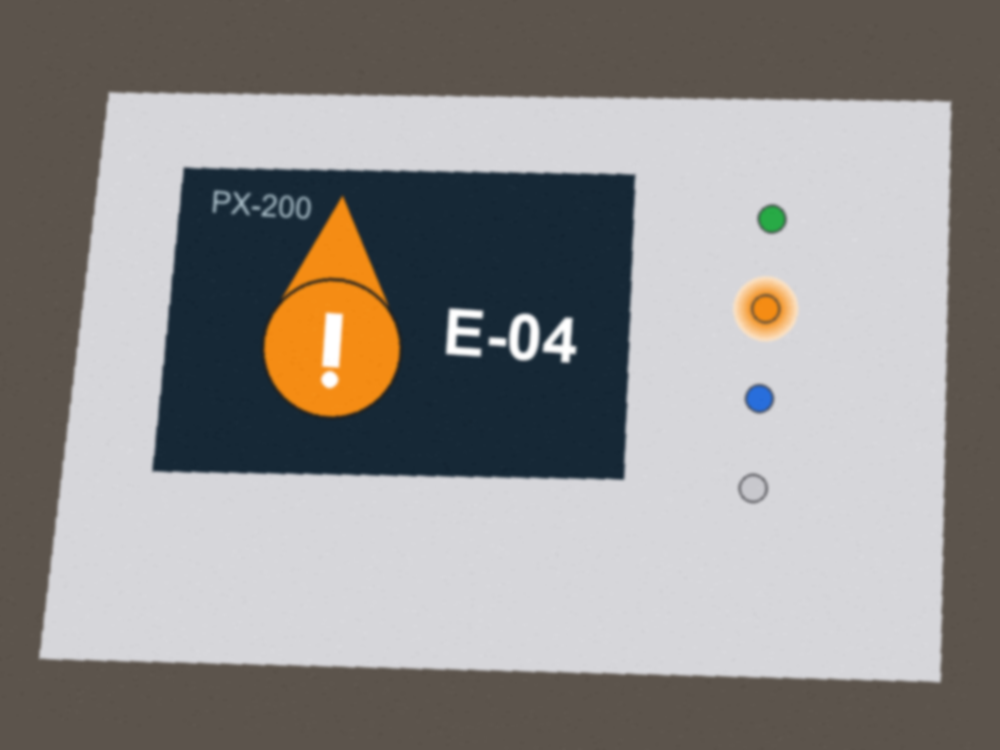

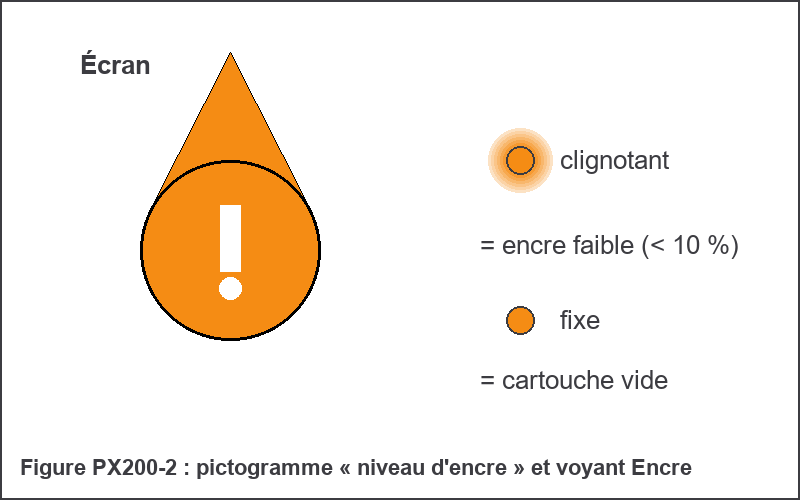

In [2]:
display(Image(filename=DONNEES / "images_clients" / "img_px200_01.png", width=420))
display(Image(filename=DONNEES / "figures" / "fig_px200_picto_encre.png", width=420))

In [3]:
figures = json.loads((DONNEES / "figures" / "figures.json").read_text(encoding="utf-8"))
print("Figures des manuels :")
for f in figures:
    print(f"  {f['id']:15s} {f['manuel']:16s} § {f['section']}")
print("\nManuels :", [p.name for p in (DONNEES / "manuels").glob("*.md")])
print("\nExtrait du manuel PX-200, section 3.1 :")
manuel = (DONNEES / "manuels" / "manuel_px200.md").read_text(encoding="utf-8")
print(manuel[manuel.index("### 3.1"):manuel.index("### 3.2")])

Figures des manuels :
  Figure PX200-1  manuel_px200.md  § 2. Panneau de commande
  Figure PX200-2  manuel_px200.md  § 3.1 Pictogramme « niveau d'encre »
  Figure PX200-3  manuel_px200.md  § 3.2 Pictogramme « bourrage papier »
  Figure PX200-4  manuel_px200.md  § 3.3 Pictogramme « Wi-Fi déconnecté »
  Figure SC10-1   manuel_sc10.md   § 2. Voyant d'état

Manuels : ['manuel_px200.md', 'manuel_sc10.md']

Extrait du manuel PX-200, section 3.1 :
### 3.1 Pictogramme « niveau d'encre » (goutte orange avec point d'exclamation)

Voir la Figure PX200-2. Une goutte orange contenant un point d'exclamation indique un problème d'encre.
- Goutte affichée **et voyant Encre orange clignotant** : niveau d'encre faible, moins de 10 % dans au moins une cartouche. L'écran affiche le code **E-04**. L'impression reste possible quelques dizaines de pages ; prévoir une cartouche de remplacement.
- Goutte affichée **et voyant Encre orange fixe** : cartouche vide ou non reconnue, code **E-05**. L'impression est 

## 2. L'agent RAG multimodal (derrière le tool distant)

`sav/rag_multimodal.py` :
- **Indexation** : les manuels sont découpés par section (`MarkdownHeaderTextSplitter`) ; chaque **figure** est décrite par le LLM vision (`gpt-4.1-mini`), et sa légende + sa description sont indexées dans la **même base FAISS** que le texte (métadonnée `type` = `texte` ou `figure`).
- **Agent RAG** : `create_agent` avec deux tools, `rechercher_passages` et `rechercher_figures` (filtre sur le type). La **photo du client est donnée en entrée au LLM** : l'agent la regarde, cherche les figures et passages correspondants, puis rédige une réponse **sourcée** (`[manuel § section]`, `[Figure ...]`).

In [4]:
sys.path.insert(0, "sav")
from rag_multimodal import CACHE_DESCRIPTIONS, charger_index, creer_embeddings, creer_llm

index_sav = charger_index(creer_llm(), creer_embeddings())
types = [d.metadata["type"] for d in index_sav.docstore._dict.values()]
print(f"Éléments indexés : {len(types)} ({types.count('texte')} passages de texte, {types.count('figure')} figures)")
print("\nDescription visuelle générée pour la Figure PX200-2 :")
print(json.loads(CACHE_DESCRIPTIONS.read_text(encoding="utf-8"))["Figure PX200-2"])

Éléments indexés : 18 (13 passages de texte, 5 figures)

Description visuelle générée pour la Figure PX200-2 :
La figure montre un pictogramme orange en forme de goutte d’encre avec un point d’exclamation blanc au centre. À droite, deux voyants ronds orange sont illustrés : un clignotant entouré d’un halo orange, signifiant « encre faible (< 10 %) », et un fixe, signifiant « cartouche vide ». Le texte « Écran » est placé en haut à gauche. La légende en bas précise « Figure PX200-2 : pictogramme « niveau d'encre » et voyant Encre ».


## 3. Démarrage du serveur MCP (tool distant `rag_multimodal`)

Dans un terminal : `uv run python sav/serveur_mcp_rag.py` (port 24001). Ici, lancé en arrière-plan depuis le notebook.

In [5]:
def port_ouvert(port: int) -> bool:
    with socket.socket() as s:
        s.settimeout(1)
        return s.connect_ex(("127.0.0.1", port)) == 0


log_serveur = open("serveur_mcp_sav.log", "w", encoding="utf-8")
serveur_sav = subprocess.Popen([sys.executable, "sav/serveur_mcp_rag.py"], stdout=log_serveur, stderr=subprocess.STDOUT,
                               env={**os.environ, "PYTHONIOENCODING": "utf-8"})
for _ in range(60):
    if port_ouvert(24001):
        break
    time.sleep(1)
print("Serveur MCP SAV joignable :", port_ouvert(24001))

Serveur MCP SAV joignable : True


## 4. Le client MCP de l'agent documentaire

In [6]:
from langchain_mcp_adapters.client import MultiServerMCPClient

client_mcp = MultiServerMCPClient({
    "sav": {"transport": "streamable_http", "url": "http://127.0.0.1:24001/mcp"},
})
outils_distants = await client_mcp.get_tools()
for outil in outils_distants:
    print(f"Tool distant : {outil.name}\n  paramètres : {json.dumps(outil.args, ensure_ascii=False)}\n  description : {outil.description}")

Tool distant : rag_multimodal
  paramètres : {"question": {"title": "Question", "type": "string"}, "image_ref": {"anyOf": [{"type": "string"}, {"type": "null"}], "default": null, "title": "Image Ref"}}
  description : Assistance documentaire du SAV (imprimante PX-200, scanner SC-10) : explique un voyant, un pictogramme,
    un code d'erreur ou une procédure de dépannage à partir des manuels (passages ET figures).
    image_ref : référence facultative d'une photo envoyée par le client (ex. « img_px200_01 »), analysée par le LLM vision.
    Renvoie la réponse rédigée et la liste des sources utilisées.


## 5. Le tool local de l'agent garantie : `consulter_garantie`

Le registre est chargé une fois dans une structure **non modifiable** (tuple de `MappingProxyType`) et le tool ne propose **aucune écriture** : lecture seule.

In [7]:
import calendar
from types import MappingProxyType

from langchain.tools import tool

def ajouter_mois(jour: date, mois: int) -> date:
    annee, m = divmod(jour.month - 1 + mois, 12)
    annee += jour.year
    return date(annee, m + 1, min(jour.day, calendar.monthrange(annee, m + 1)[1]))


REGISTRE = tuple(MappingProxyType(entree) for entree in
                 json.loads((DONNEES / "registre_garanties.json").read_text(encoding="utf-8")))


@tool
def consulter_garantie(numero_serie: str) -> dict:
    """Consulte le registre des garanties (lecture seule) à partir du numéro de série d'un appareil
    (format PX200-XXXX ou SC10-XXXX). Renvoie le modèle, la date d'achat, la date de fin de garantie et le statut."""
    numero = numero_serie.strip().upper()
    entree = next((e for e in REGISTRE if e["numero_serie"] == numero), None)
    if entree is None:
        return {"numero_serie": numero, "trouve": False, "message": "Numéro de série absent du registre."}
    achat = date.fromisoformat(entree["date_achat"])
    fin = ajouter_mois(achat, entree["duree_garantie_mois"])
    aujourd_hui = date.today()
    return {
        "numero_serie": numero, "trouve": True, "modele": entree["modele"],
        "date_achat": achat.isoformat(), "duree_garantie_mois": entree["duree_garantie_mois"],
        "fin_garantie": fin.isoformat(), "date_verification": aujourd_hui.isoformat(),
        "sous_garantie": aujourd_hui <= fin,
        "jours_restants": max((fin - aujourd_hui).days, 0),
    }


for numero in ["PX200-0042", "PX200-0017", "PX200-9999"]:
    print(consulter_garantie.invoke({"numero_serie": numero}))

{'numero_serie': 'PX200-0042', 'trouve': True, 'modele': 'Imprimante PX-200', 'date_achat': '2025-06-14', 'duree_garantie_mois': 24, 'fin_garantie': '2027-06-14', 'date_verification': '2026-11-26', 'sous_garantie': True, 'jours_restants': 200}
{'numero_serie': 'PX200-0017', 'trouve': True, 'modele': 'Imprimante PX-200', 'date_achat': '2023-02-03', 'duree_garantie_mois': 24, 'fin_garantie': '2025-02-03', 'date_verification': '2026-11-26', 'sous_garantie': False, 'jours_restants': 0}
{'numero_serie': 'PX200-9999', 'trouve': False, 'message': 'Numéro de série absent du registre.'}


## 6. Les deux agents spécialisés

In [8]:
from langchain.agents import create_agent
from langchain.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_openai import AzureChatOpenAI

llm = AzureChatOpenAI(
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    api_version=os.getenv("AZURE_OPENAI_API_VERSION"),
    azure_deployment=os.getenv("AZURE_OPENAI_DEPLOYMENT"),
    temperature=0,
    timeout=120,
)

agent_doc = create_agent(
    model=llm,
    tools=outils_distants,
    system_prompt=(
        "Tu es l'agent documentaire du SAV. Pour chaque demande, appelle le tool distant rag_multimodal avec la question "
        "du client et, si une photo est jointe, sa référence exacte dans image_ref. Restitue ensuite au client une réponse "
        "claire en français, en conservant les références des sources ([manuel § section], [Figure ...]). N'ajoute rien qui "
        "ne vienne pas du tool."
    ),
)

agent_gar = create_agent(
    model=llm,
    tools=[consulter_garantie],
    system_prompt=(
        "Tu es l'agent garantie du SAV. Extrais le numéro de série de la demande, appelle consulter_garantie, puis réponds "
        "en français : appareil, date d'achat, date de fin de garantie, statut (sous garantie ou non) et jours restants. "
        "Si le numéro est absent ou introuvable, demande au client de le vérifier (étiquette sous l'appareil)."
    ),
)

## 7. L'orchestrateur LangGraph

- **État** : demande, référence de la photo, catégorie, agent sélectionné, réponse finale, trace d'exécution
- **orchestrateur** : si une réponse finale existe → **fin** ; sinon il **classe** la demande dans **une seule** catégorie (*structured output*) et sélectionne l'agent
- **agent_documentaire / agent_garantie** : traitent la demande puis **rendent la main** à l'orchestrateur

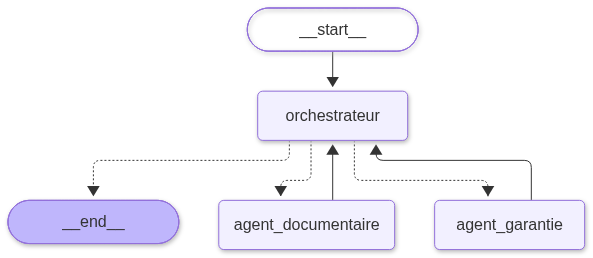

In [9]:
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field


class EtatSAV(TypedDict, total=False):
    demande: str
    image_ref: str | None
    categorie: Literal["documentation", "garantie"]
    agent: Literal["agent_documentaire", "agent_garantie"]
    reponse_finale: str
    trace: Annotated[list[str], operator.add]


class Classification(BaseModel):
    """Catégorie unique d'une demande adressée au SAV."""
    categorie: Literal["documentation", "garantie"] = Field(
        description="documentation : dépannage, signification d'un voyant, d'un pictogramme, d'un code, procédure ; "
                    "garantie : vérifier si un appareil est couvert, à partir d'un numéro de série")
    justification: str = Field(description="Raison du choix, en une phrase")


classifieur = llm.with_structured_output(Classification)
AGENT_PAR_CATEGORIE = {"documentation": "agent_documentaire", "garantie": "agent_garantie"}


async def orchestrateur(etat: EtatSAV) -> dict:
    if etat.get("reponse_finale"):
        return {"trace": ["orchestrateur : réponse finale disponible -> fin de l'exécution"]}
    classification = await classifieur.ainvoke([
        SystemMessage("Tu es l'orchestrateur du SAV. Classe la demande dans UNE SEULE catégorie : documentation ou garantie."),
        HumanMessage(f"Demande : {etat['demande']}\nPhoto jointe : {etat.get('image_ref') or 'aucune'}"),
    ])
    agent = AGENT_PAR_CATEGORIE[classification.categorie]
    return {"categorie": classification.categorie, "agent": agent,
            "trace": [f"orchestrateur : catégorie « {classification.categorie} » -> {agent} ({classification.justification})"]}


def router(etat: EtatSAV) -> Literal["agent_documentaire", "agent_garantie", "__end__"]:
    return END if etat.get("reponse_finale") else etat["agent"]


def appels_de_tools(messages) -> list[str]:
    return [f"{tc['name']}({json.dumps(tc['args'], ensure_ascii=False)})"
            for m in messages if isinstance(m, AIMessage) for tc in m.tool_calls]


async def agent_documentaire(etat: EtatSAV) -> dict:
    texte = f"Demande du client : {etat['demande']}"
    if etat.get("image_ref"):
        texte += f"\nRéférence de la photo jointe : {etat['image_ref']}"
    resultat = await agent_doc.ainvoke({"messages": [HumanMessage(texte)]})
    return {"reponse_finale": resultat["messages"][-1].content,
            "trace": [f"agent_documentaire : client MCP -> {', '.join(appels_de_tools(resultat['messages']))}"]}


async def agent_garantie(etat: EtatSAV) -> dict:
    resultat = await agent_gar.ainvoke({"messages": [HumanMessage(etat["demande"])]})
    return {"reponse_finale": resultat["messages"][-1].content,
            "trace": [f"agent_garantie : tool local -> {', '.join(appels_de_tools(resultat['messages']))}"]}


workflow = StateGraph(EtatSAV)
workflow.add_node("orchestrateur", orchestrateur)
workflow.add_node("agent_documentaire", agent_documentaire)
workflow.add_node("agent_garantie", agent_garantie)
workflow.add_edge(START, "orchestrateur")
workflow.add_conditional_edges("orchestrateur", router)
workflow.add_edge("agent_documentaire", "orchestrateur")
workflow.add_edge("agent_garantie", "orchestrateur")
sav = workflow.compile()

try:
    display(Image(sav.get_graph().draw_mermaid_png()))
except Exception:
    print(sav.get_graph().draw_mermaid())

In [10]:
async def traiter(demande: str, image_ref: str | None = None) -> dict:
    etat = await sav.ainvoke({"demande": demande, "image_ref": image_ref, "trace": []})
    print(f"Demande : {demande}" + (f"\nPhoto : {image_ref}" if image_ref else ""))
    print(f"Catégorie : {etat['categorie']} · Agent : {etat['agent']}\n")
    print("Trace :")
    for ligne in etat["trace"]:
        print("  -", ligne)
    print("\nRéponse finale :")
    display(Markdown(etat["reponse_finale"]))
    return etat

## 8. Exemple 1 — Assistance documentaire

« Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ? » — photo `img_px200_01`.

Attendu : catégorie **documentation** · agent **agent_documentaire**.

In [11]:
exemple_1 = await traiter(
    "Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?",
    image_ref="img_px200_01",
)

Demande : Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?
Photo : img_px200_01
Catégorie : documentation · Agent : agent_documentaire

Trace :
  - orchestrateur : catégorie « documentation » -> agent_documentaire (La demande concerne la signification d'un voyant clignotant sur un appareil, ce qui relève de la documentation technique.)
  - agent_documentaire : client MCP -> rag_multimodal({"question": "Que signifie le voyant clignotant sur l'imprimante PX-200 ?", "image_ref": "img_px200_01"})
  - orchestrateur : réponse finale disponible -> fin de l'exécution

Réponse finale :


Le voyant orange clignotant sur votre imprimante PX-200, accompagné du pictogramme en forme de goutte d'encre avec un point d'exclamation, signifie que le niveau d'encre est faible, inférieur à 10 % dans au moins une cartouche. L'écran affiche alors le code d'erreur E-04.

Voici ce que vous pouvez faire :
1. Le voyant Encre orange clignotant indique un niveau d'encre faible (< 10 %) dans une cartouche.
2. Le code affiché à l'écran est E-04.
3. L'impression reste possible pendant encore quelques dizaines de pages, mais il est conseillé de prévoir une cartouche de remplacement.
4. Pour savoir quelle cartouche est concernée, appuyez sur le bouton OK lorsque la goutte est affichée : l'écran indiquera le niveau d'encre de chaque couleur.
5. Lorsque la cartouche est remplacée, l'imprimante effectue un nettoyage automatique et le voyant Encre s'éteint, le code E-04 disparaît.

Vous trouverez ces informations dans le manuel PX-200, section 3.1 Pictogramme « niveau d'encre » et section 6 Codes d'erreur, ainsi que la figure PX200-2 illustrant ce pictogramme.

## 9. Exemple 2 — Vérification de garantie

« Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042. »

Attendu : catégorie **garantie** · agent **agent_garantie**.

In [12]:
exemple_2 = await traiter("Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042.")

Demande : Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042.
Catégorie : garantie · Agent : agent_garantie

Trace :
  - orchestrateur : catégorie « garantie » -> agent_garantie (La demande concerne la vérification de la couverture de garantie d'un appareil à partir de son numéro de série.)
  - agent_garantie : tool local -> consulter_garantie({"numero_serie": "PX200-0042"})
  - orchestrateur : réponse finale disponible -> fin de l'exécution

Réponse finale :


Votre imprimante PX-200, achetée le 14 juin 2025, est encore sous garantie. La garantie se termine le 14 juin 2027. Il vous reste 200 jours de garantie.

## 10. Tests complémentaires

Garantie expirée, numéro inconnu, dépannage sans photo, autre appareil : on vérifie la catégorie et l'agent choisis par l'orchestrateur.

In [13]:
tests = [
    ("Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?", "img_px200_01", "documentation"),
    ("Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042.", None, "garantie"),
    ("Mon imprimante PX200-0017 est-elle toujours couverte ?", None, "garantie"),
    ("Le numéro de série de mon scanner est SC10-7777, est-il garanti ?", None, "garantie"),
    ("Une feuille est coincée dans ma PX-200 et le voyant rouge est allumé, que faire ?", None, "documentation"),
    ("Le voyant de mon scanner SC-10 clignote en rouge, c'est grave ?", None, "documentation"),
]

lignes = ["| Demande | Photo | Attendu | Obtenu | Agent | Extrait de la réponse |", "|---|---|---|---|---|---|"]
for demande, image_ref, attendu in tests:
    etat = await sav.ainvoke({"demande": demande, "image_ref": image_ref, "trace": []})
    ok = "✅" if etat["categorie"] == attendu else "❌"
    extrait = etat["reponse_finale"].replace("\n", " ")[:160].replace("|", "/")
    lignes.append(f"| {demande} | {image_ref or '—'} | {attendu} | {ok} {etat['categorie']} | {etat['agent']} | {extrait}… |")
display(Markdown("\n".join(lignes)))

| Demande | Photo | Attendu | Obtenu | Agent | Extrait de la réponse |
|---|---|---|---|---|---|
| Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ? | img_px200_01 | documentation | ✅ documentation | agent_documentaire | Le voyant orange clignotant sur votre imprimante PX-200, accompagné du pictogramme en forme de goutte d'encre orange avec un point d'exclamation, signifie que l… |
| Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042. | — | garantie | ✅ garantie | agent_garantie | Votre imprimante PX-200, achetée le 14 juin 2025, est encore sous garantie. La garantie se termine le 14 juin 2027. Il vous reste 200 jours de garantie.… |
| Mon imprimante PX200-0017 est-elle toujours couverte ? | — | garantie | ✅ garantie | agent_garantie | Votre imprimante PX-200, achetée le 3 février 2023, n'est plus sous garantie. La garantie de 24 mois s'est terminée le 3 février 2025. Il n'y a donc plus de jou… |
| Le numéro de série de mon scanner est SC10-7777, est-il garanti ? | — | garantie | ✅ garantie | agent_garantie | Le numéro de série SC10-7777 n'a pas été trouvé dans notre registre. Pouvez-vous vérifier le numéro de série sur l'étiquette sous votre appareil et me le commun… |
| Une feuille est coincée dans ma PX-200 et le voyant rouge est allumé, que faire ? | — | documentation | ✅ documentation | agent_documentaire | Le voyant rouge allumé sur votre imprimante PX-200 indique un bourrage papier, correspondant au code d'erreur E-02. Voici la procédure à suivre pour résoudre ce… |
| Le voyant de mon scanner SC-10 clignote en rouge, c'est grave ? | — | documentation | ✅ documentation | agent_documentaire | Le voyant rouge clignotant sur votre scanner SC-10 signifie que la tête de lecture est verrouillée, probablement parce que le verrou de transport est activé. Po… |

## 11. Arrêt du serveur MCP

In [14]:
import psutil

# Sous Windows, le python.exe d'un environnement uv lance l'interpréteur réel en processus enfant : on arrête les deux
processus = psutil.Process(serveur_sav.pid)
for p in processus.children(recursive=True) + [processus]:
    p.kill()
time.sleep(1)
log_serveur.close()
print("Serveur MCP SAV arrêté | port 24001 ouvert :", port_ouvert(24001))

Serveur MCP SAV arrêté | port 24001 ouvert : False


**Bilan :**
- L'**orchestrateur LangGraph** classe chaque demande dans une seule catégorie, délègue à l'agent spécialisé, reprend la main et termine dès qu'une réponse finale existe.
- L'**agent documentaire** n'a qu'un tool, **distant** : il passe par un **client MCP** (streamable-http) ; le RAG multimodal peut évoluer (nouveaux manuels, autre modèle) sans modifier l'agent.
- Le **RAG multimodal** combine passages, figures (décrites par le LLM vision à l'indexation) et la photo du client (donnée en entrée au LLM) pour produire une réponse **sourcée**.
- L'**agent garantie** utilise un tool **local** qui consulte le registre en **lecture seule**.